<a href="https://colab.research.google.com/github/francisco-mreina/olist-Predict-Insatisfaction-and-delay/blob/main/04_interpretabilidad_shap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de clientes Olist (Brazilian E-Commerce)

## 7. Interpretabilidad y diagnóstico de causas

### 7.1. SHAP / Feature Importance

Los modelos de árboles (Random Forest, XGBoost) entrenados en el capítulo 6.2 mejoran el ajuste respecto a la regresión logística, pero pierden la lectura directa de coeficientes. Para recuperar esa interpretabilidad se aplica **SHAP** (*SHapley Additive exPlanations*) sobre los modelos XGBoost de ambos problemas (`xgb_insat`, `xgb_retraso`), por ser los de mayor complejidad y los que más lo necesitan.

Antes de calcular los valores SHAP, se reconstruyen explícitamente los conjuntos de test utilizados al entrenar `xgb_insat` y `xgb_retraso` en el capítulo 6.2 (misma selección de columnas, mismas *dummies* de `customer_region` y misma semilla `random_state=42`), ya que las variables genéricas `X_train`/`X_test` fueron sobrescritas por los bloques de código posteriores.

In [ ]:
# Insatisfacción
X_insat_shap = imput[predictores_insat_red].copy()
X_insat_shap = pd.get_dummies(X_insat_shap, columns=['customer_region'], drop_first=True)
y_insat_shap = insatisfaccion.copy()

X_train_insat_shap, X_test_insat_shap, y_train_insat_shap, y_test_insat_shap = train_test_split(
    X_insat_shap, y_insat_shap,
    test_size=0.2,
    random_state=42,
    stratify=y_insat_shap
)

# Retraso (solo pedidos entregados)
entregado_mask = imput['order_status'] == 'delivered'

X_retraso_shap = imput.loc[entregado_mask, predictores_retraso_red].copy()
X_retraso_shap = pd.get_dummies(X_retraso_shap, columns=['customer_region'], drop_first=True)
y_retraso_shap = retraso.loc[entregado_mask].copy()

X_train_retraso_shap, X_test_retraso_shap, y_train_retraso_shap, y_test_retraso_shap = train_test_split(
    X_retraso_shap, y_retraso_shap,
    test_size=0.2,
    random_state=42,
    stratify=y_retraso_shap
)

print('Test insatisfacción:', X_test_insat_shap.shape)
print('Test retraso:', X_test_retraso_shap.shape)

Test insatisfacción: (19889, 9)
Test retraso: (19296, 11)


#### SHAP — Insatisfacción

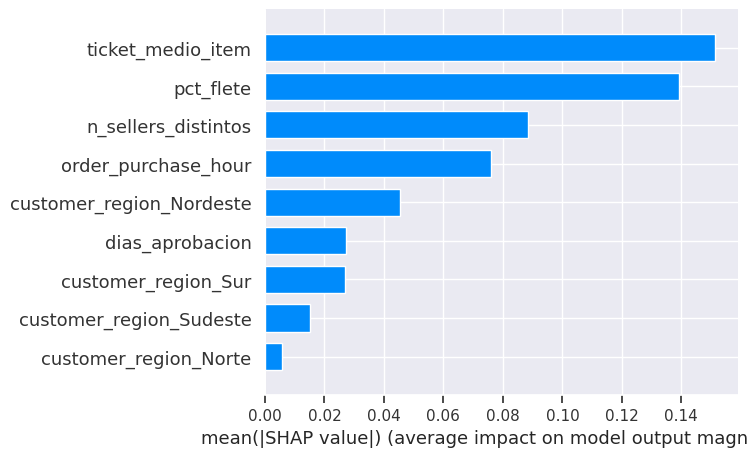

In [ ]:
# Explainer para modelos de árboles (rápido y exacto para XGBoost)
explainer_insat = shap.TreeExplainer(xgb_insat)
shap_values_insat = explainer_insat.shap_values(X_test_insat_shap)

# Importancia media por variables
shap.summary_plot(shap_values_insat, X_test_insat_shap, plot_type='bar', show=True)

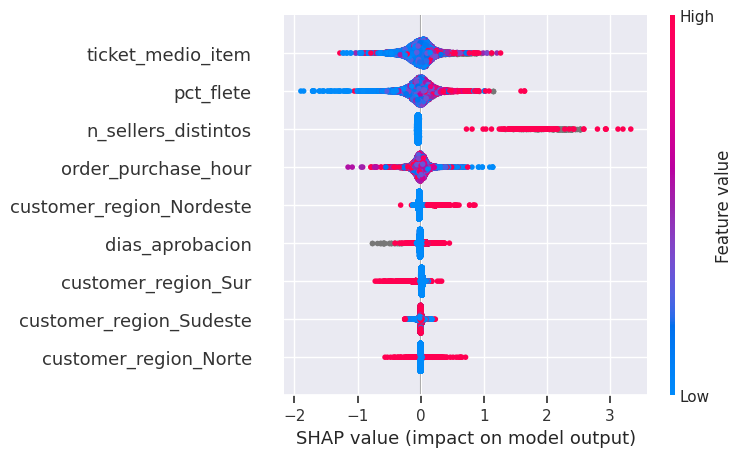

In [ ]:
# Distribución de impacto por variable (beeswarm): dirección y magnitud del efecto
shap.summary_plot(shap_values_insat, X_test_insat_shap, show=True)

#### SHAP — Retraso

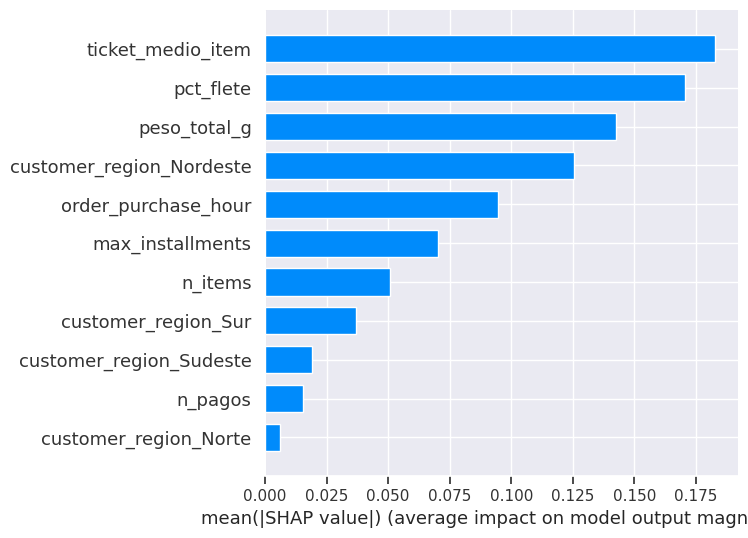

In [ ]:
explainer_retraso = shap.TreeExplainer(xgb_retraso)
shap_values_retraso = explainer_retraso.shap_values(X_test_retraso_shap)

shap.summary_plot(shap_values_retraso, X_test_retraso_shap, plot_type='bar', show=True)

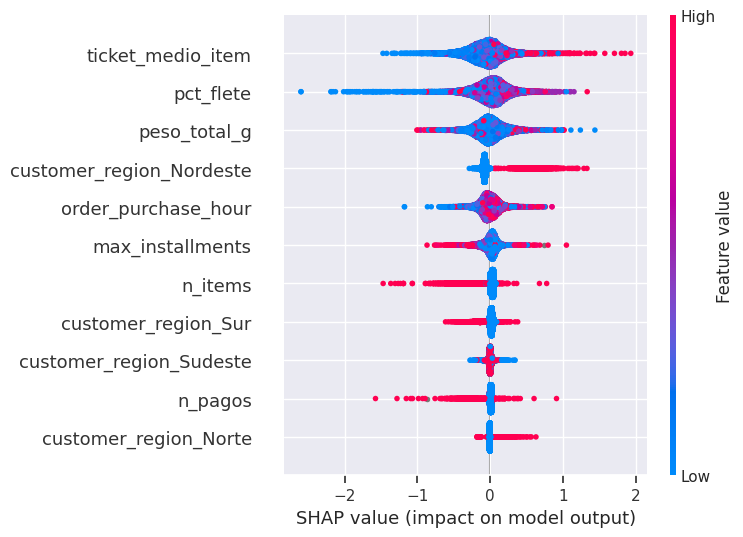

In [ ]:
shap.summary_plot(shap_values_retraso, X_test_retraso_shap, show=True)

### 7.2. Factores que más influyen en insatisfacción y retraso

Para poder documentar la comparación en la memoria (y contrastarla con los coeficientes del modelo logístico del capítulo 6.1 y con el ranking de V de Cramér del capítulo 5), se construye una tabla con la importancia media de cada variable (media de |SHAP|) para cada uno de los dos problemas.

In [ ]:
# Tabla de importancia SHAP — Insatisfacción
importancia_shap_insat = pd.DataFrame({
    'variable': X_test_insat_shap.columns,
    'shap_abs_medio': np.abs(shap_values_insat).mean(axis=0)
}).sort_values('shap_abs_medio', ascending=False).reset_index(drop=True)

print('Importancia SHAP — Insatisfacción')
display(importancia_shap_insat)

# Tabla de importancia SHAP — Retraso
importancia_shap_retraso = pd.DataFrame({
    'variable': X_test_retraso_shap.columns,
    'shap_abs_medio': np.abs(shap_values_retraso).mean(axis=0)
}).sort_values('shap_abs_medio', ascending=False).reset_index(drop=True)

print('Importancia SHAP — Retraso')
display(importancia_shap_retraso)

Importancia SHAP — Insatisfacción


,variable,shap_abs_medio
0,ticket_medio_item,0.151467
1,pct_flete,0.139236
2,n_sellers_distintos,0.088416
3,order_purchase_hour,0.075852
4,customer_region_Nordeste,0.045553
5,dias_aprobacion,0.027303
6,customer_region_Sur,0.026897
7,customer_region_Sudeste,0.015166
8,customer_region_Norte,0.005667


Importancia SHAP — Retraso


,variable,shap_abs_medio
0,ticket_medio_item,0.182869
1,pct_flete,0.170511
2,peso_total_g,0.142588
3,customer_region_Nordeste,0.125396
4,order_purchase_hour,0.094498
5,max_installments,0.070045
6,n_items,0.050606
7,customer_region_Sur,0.036810
8,customer_region_Sudeste,0.019193
9,n_pagos,0.015349


## Próximos pasos

- Capitulo 8
- Capítulo 9:** para el análisis a nivel de item/categoría, partir de `order_items` original (no de esta tabla agregada a nivel de pedido)